# Formas de onda sísmicas: QC, filtrado y primeros picks

**Nivel 1 — Fundamentos y medición** · 45–60 min

## Objetivos
- Inspeccionar procedencia, unidades, orden de canales, muestreo y referencias de analistas.
- Aplicar el filtro Butterworth y detector STA/LTA del producto con controles editables.
- Medir residuales frente a referencias mientras se varían ruido sintético, banda y umbral.

## Preparación

Ejecute desde la raíz en el entorno fijado:
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8

La celda experimental imprime las versiones activas.

## Datos
Entrada: una traza del subconjunto derivado de STEAD comprometido para el navegador. Las muestras son conteos instrumentales normalizados, sin restitución; este artefacto carece de respuesta instrumental para expresar movimiento físico del suelo. Los picks de analistas son referencias, no verdad geológica. El ruido agregado es sintético y reproducible. Ningún resultado describe una nueva observación de terreno.

## Método

Con intervalo Δt e índice n, el tiempo es tₙ=nΔt. Inspeccione los contratos de adquisición antes de filtrar: una traza plausible no corrige orientación, reloj, respuesta o datum erróneos.

La ruta del producto en data-pipeline/waveform_processing.py remueve la respuesta cuando MiniSEED y StationXML lo permiten, aplica un pasabanda Butterworth SOS de cuarto orden hacia adelante y atrás, y calcula una razón de energía entre ventanas corta y larga. Para tres componentes x[n], la característica es aproximadamente C[n]=STA(Σc x_c²)/LTA(Σc x_c²). Un cruce ascendente marca onset. El segundo cruce suficientemente separado se denomina S solo provisionalmente; STA/LTA no clasifica fases.

La traza del navegador ya está normalizada y carece de metadatos de respuesta. Reproducimos el diseño de filtro SOS Butterworth del producto y usamos su detector STA/LTA real, pero no cargamos el contrato ObsPy fijado del motor ni ejecutamos ingesta MiniSEED, corrección de respuesta o QC completo M08. Agregamos una realización normal estándar con semilla a varias fracciones de la desviación estándar. Comparamos picks con referencias suministradas; residuales absolutos y omisiones son diagnósticos de concordancia en una traza, no estimaciones de exactitud.

### Preguntas
1. ¿Qué canal/ventana domina la razón de energía y qué elimina el filtro?
2. ¿Un umbral mayor reduce disparos tempranos o hace omitir un onset anotado?
3. ¿Por qué un residual menor frente al analista no establece exactitud física?

### Experimento 1 — edite controles y compare el barrido

Los niveles reutilizan una misma realización con semilla para aislar amplitud. Filtro y umbral varían por separado. Use None para omitir filtrado.

In [1]:
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'scipy', 'matplotlib']})
# Reproducible notebook experiment cell.
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data').is_dir() and (p/'data-pipeline').is_dir())
sys.path.insert(0, str(root/'data-pipeline'))
from scipy.signal import butter, sosfiltfilt
from phase_picking import classical_stalta_picks
base = root/'data/derived/phase/browser-assets/stead'
manifest = json.loads((base/'manifest.json').read_text(encoding='utf-8'))
record = manifest['records'][0]
raw = np.fromfile(base/record['waveform_file'], dtype='<f4').reshape(manifest['input']['shape'])[0].T.astype(float)
fs = float(manifest['input']['sample_rate_hz']); dt = 1/fs
labels = {'P': record['analyst_p_s'], 'S': record['analyst_s_s']}
bench = json.loads((root/'data/derived/phase/stead-heldout-benchmark.json').read_text(encoding='utf-8'))
pars = bench['classical_parameters']
print('Trace', record['trace_id'], raw.shape, 'sample x component; fs=', fs, 'Hz; units=', manifest['input']['unit'])
print('Channels', manifest['input']['component_order'], '| analyst reference times (s):', labels)
FILTER_BAND_HZ = (1.0, 12.0)  # set None to bypass
ADDED_NOISE_FRACTION = 0.25    # relative to trace standard deviation
TRIGGER_RATIO = float(pars['trigger_ratio'])
STA_SECONDS = float(pars['STA_s']); LTA_SECONDS = float(pars['LTA_s'])
MINIMUM_PS_SECONDS = float(pars['minimum_PS_s'])
SEED = 20261027
noise_unit = np.random.default_rng(SEED).standard_normal(raw.shape)
noise = noise_unit * np.std(raw)

def condition(values, band):
    if band is None: return values.copy(), 0
    out = np.empty_like(values); pads = []
    for c in range(values.shape[1]):
        sos = butter(4, band, btype='bandpass', fs=fs, output='sos')
        pad = 3*(2*len(sos)+1-min(int((sos[:,2]==0).sum()),int((sos[:,5]==0).sum())))
        out[:, c] = sosfiltfilt(sos, values[:, c], padtype='odd', padlen=pad)
        if not np.isfinite(out[:,c]).all(): raise ValueError('non-finite filter output')
        pads.append(pad)
    return out, max(pads)

def trial(band, noise_fraction, threshold):
    filtered, pad = condition(raw + noise_fraction*noise, band)
    picks = classical_stalta_picks(filtered, sample_interval_s=dt, threshold=threshold,
        sta_s=STA_SECONDS, lta_s=LTA_SECONDS, minimum_ps_s=MINIMUM_PS_SECONDS)
    row = {'band_Hz': 'off' if band is None else f'{band[0]:g}-{band[1]:g}',
           'added_noise_fraction': noise_fraction, 'threshold': threshold, 'filter_pad_samples': pad}
    for phase in ('P', 'S'):
        t = picks[phase]
        row[f'{phase}_pick_s'] = np.nan if t is None else t
        row[f'{phase}_abs_residual_s'] = np.nan if t is None else abs(t-labels[phase])
        row[f'{phase}_detected'] = t is not None
    return filtered, picks, row

configs = [(None,0,TRIGGER_RATIO), ((1,12),0,TRIGGER_RATIO),
           ((1,12),.25,TRIGGER_RATIO), ((3,10),.75,TRIGGER_RATIO),
           ((3,10),.75,3.2)]
table = pd.DataFrame([trial(*cfg)[2] for cfg in configs])
display(table.round(4))
selected, picks, _ = trial(FILTER_BAND_HZ, ADDED_NOISE_FRACTION, TRIGGER_RATIO)
print('Selected controls:', FILTER_BAND_HZ, ADDED_NOISE_FRACTION, TRIGGER_RATIO,
      'STA/LTA/min P-S:', STA_SECONDS, LTA_SECONDS, MINIMUM_PS_SECONDS, 'seed:', SEED)
print('Selected picks (s):', picks)
print('Missing pick means missed onset; the second eligible trigger is only provisionally named S.')


Runtime versions: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}
Trace B917.PB_20110107214856_EV (6000, 3) sample x component; fs= 100.0 Hz; units= dimensionless normalized instrument counts
Channels ['E', 'N', 'Z'] | analyst reference times (s): {'P': 7.0, 'S': 12.77}


,band_Hz,added_noise_fraction,threshold,filter_pad_samples,P_pick_s,P_abs_residual_s,P_detected,S_pick_s,S_abs_residual_s,S_detected
0,off,0.00,2.5,0,1.19,5.81,True,7.02,5.75,True
1,1-12,0.00,2.5,27,1.19,5.81,True,6.95,5.82,True
2,1-12,0.25,2.5,27,6.99,0.01,True,12.81,0.04,True
3,3-10,0.75,2.5,27,4.55,2.45,True,5.50,7.27,True
4,3-10,0.75,3.2,27,7.02,0.02,True,12.81,0.04,True


Selected controls: (1.0, 12.0) 0.25 2.5 STA/LTA/min P-S: 0.12 1.2 0.4 seed: 20261027
Selected picks (s): {'P': 6.99, 'S': 12.81}
Missing pick means missed onset; the second eligible trigger is only provisionally named S.


### Diagnóstico 2 — inspeccione la traza y los resultados temporales

Los marcadores muestran referencias de analistas y salida del detector. La traza sigue controles seleccionados de ruido y filtro. Compare la tabla numérica de residuales, no solo el gráfico.

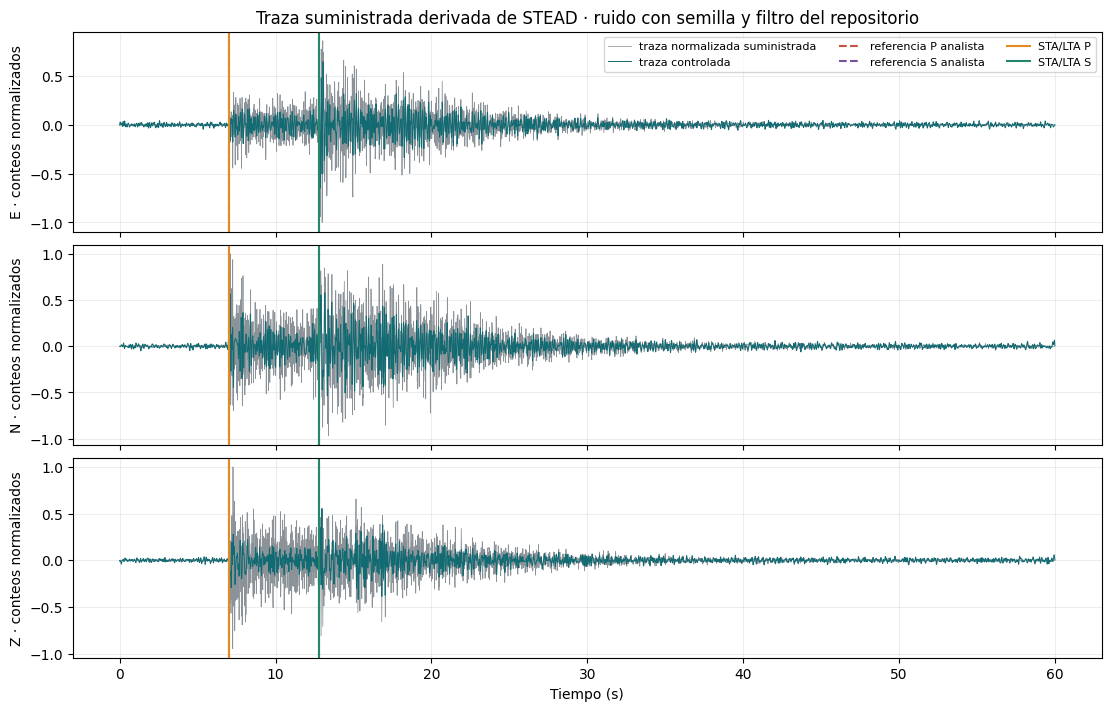

La concordancia en una traza no es puntaje poblacional ni afirmación de verdad de terreno.


In [2]:
# Reproducible notebook experiment cell.
time_s = np.arange(len(raw))*dt
names = manifest['input']['component_order']
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
for c, ax in enumerate(axes):
    ax.plot(time_s, raw[:, c], color='#8b9398', lw=.55, label='traza normalizada suministrada')
    ax.plot(time_s, selected[:, c], color='#126b73', lw=.7, label='traza controlada')
    ax.axvline(labels['P'], color='#c45442', ls='--', label='referencia P analista')
    ax.axvline(labels['S'], color='#76529b', ls='--', label='referencia S analista')
    for phase, color in (('P','#e28b22'),('S','#24866c')):
        if picks[phase] is not None: ax.axvline(picks[phase], color=color, label=f'STA/LTA {phase}')
    ax.set_ylabel(f'{names[c]} · conteos normalizados'); ax.grid(alpha=.22)
axes[0].legend(ncol=3, fontsize=8); axes[-1].set_xlabel('Tiempo (s)')
axes[0].set_title('Traza suministrada derivada de STEAD · ruido con semilla y filtro del repositorio')
plt.show()
print('La concordancia en una traza no es puntaje poblacional ni afirmación de verdad de terreno.')

## Resultados

Use la tabla de detecciones y residuales absolutos P/S. Indique qué ajustes cambiaron el resultado; una traza no es benchmark.

## Resumen
Informe contrato de muestreo/unidades, variable controlada, residual o pick omitido y por qué no establece exactitud de terreno.

## Referencias
- [ObsPy Stream y metadatos de forma de onda](https://docs.obspy.org/packages/autogen/obspy.core.stream.stream.html)
- Traza y manifiesto: data/derived/phase/browser-assets/stead/manifest.json
- Diseño de filtro: data-pipeline/waveform_processing.py
- Detector: data-pipeline/phase_picking.py